# Audio Deepfake Detection - Preprocessing Pipeline

This notebook sets up the preprocessing pipeline for audio deepfake detection using the ASVspoof 2021 dataset.
It extracts MFCC (Mel-Frequency Cepstral Coefficients) features, visualizes genuine vs. spoof audio spectrograms, and defines a PyTorch `AudioDataset`.

In [1]:
# 1. Imports
import os
import librosa
import librosa.display
import numpy as np
import torch
import torch.utils.data
from torch.utils.data import Dataset
import matplotlib.pyplot as plt

In [2]:
# 2. MFCC Extraction Function
def extract_mfcc(audio_path, n_mfcc=40, max_len=300):
    """
    Extract MFCC features from an audio file.
    
    Parameters:
        audio_path (str): Path to the audio file.
        n_mfcc (int): Number of MFCC coefficients to extract (default 40).
        max_len (int): Fixed length for time frames (default 300).
        
    Returns:
        np.ndarray: MFCC feature matrix of shape (n_mfcc, max_len).
    """
    y, sr = librosa.load(audio_path, sr=16000)
    mfcc = librosa.feature.mfcc(y=y, sr=16000, n_mfcc=n_mfcc, n_fft=2048, hop_length=512)
    
    if mfcc.shape[1] < max_len:
        pad_width = max_len - mfcc.shape[1]
        mfcc = np.pad(mfcc, pad_width=((0, 0), (0, pad_width)), mode="constant")
    else:
        mfcc = mfcc[:, :max_len]
        
    return mfcc

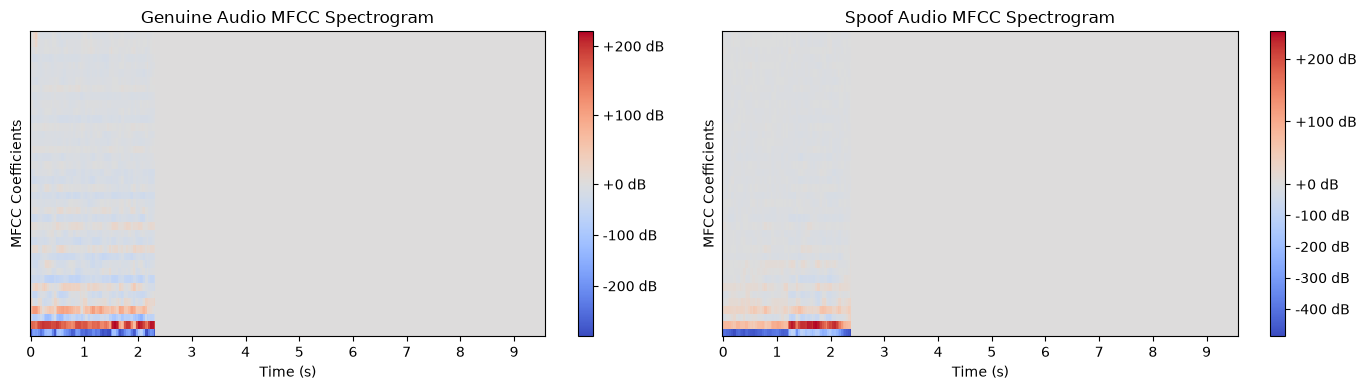

In [3]:
# 3. Visualization: Load one genuine and one spoof audio file and plot side-by-side
genuine_file = "/projects/Datasets/audio/asvspoof2021/genuine/LA_E_1001516.flac"
spoof_file = "/projects/Datasets/audio/asvspoof2021/spoof/LA_E_1000200.flac"

genuine_mfcc = extract_mfcc(genuine_file)
spoof_mfcc = extract_mfcc(spoof_file)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

ax = axes[0]
img1 = librosa.display.specshow(genuine_mfcc, sr=16000, hop_length=512, x_axis="time", ax=ax)
ax.set_title("Genuine Audio MFCC Spectrogram")
ax.set_xlabel("Time (s)")
ax.set_ylabel("MFCC Coefficients")
fig.colorbar(img1, ax=ax, format="%+2.0f dB")

ax = axes[1]
img2 = librosa.display.specshow(spoof_mfcc, sr=16000, hop_length=512, x_axis="time", ax=ax)
ax.set_title("Spoof Audio MFCC Spectrogram")
ax.set_xlabel("Time (s)")
ax.set_ylabel("MFCC Coefficients")
fig.colorbar(img2, ax=ax, format="%+2.0f dB")

plt.tight_layout()
plt.show()

In [4]:
# 4. PyTorch Dataset Class
class AudioDataset(torch.utils.data.Dataset):
    """
    PyTorch Dataset for audio deepfake classification.
    
    Args:
        file_paths (list): List of file paths to audio samples.
        labels (list): List of labels (0 for genuine, 1 for spoof).
        n_mfcc (int): Number of MFCC coefficients.
        max_len (int): Fixed maximum length for MFCC time dimension.
    """
    def __init__(self, file_paths, labels, n_mfcc=40, max_len=300):
        self.file_paths = file_paths
        self.labels = labels
        self.n_mfcc = n_mfcc
        self.max_len = max_len
        
    def __len__(self):
        return len(self.file_paths)
    
    def __getitem__(self, idx):
        audio_path = self.file_paths[idx]
        label = self.labels[idx]
        
        mfcc = extract_mfcc(audio_path, n_mfcc=self.n_mfcc, max_len=self.max_len)
        
        # Convert to tensor and add channel dimension (1, 40, 300)
        mfcc_tensor = torch.tensor(mfcc, dtype=torch.float32).unsqueeze(0)
        label_tensor = torch.tensor(label, dtype=torch.long)
        
        return mfcc_tensor, label_tensor

In [5]:
# Verify Dataset functionality
sample_files = [genuine_file, spoof_file]
sample_labels = [0, 1]  # 0 for genuine, 1 for spoof

dataset = AudioDataset(sample_files, sample_labels)
print(f"Dataset sample count: {len(dataset)}")

for i in range(len(dataset)):
    mfcc_t, lbl_t = dataset[i]
    label_str = "Genuine" if lbl_t.item() == 0 else "Spoof"
    print(f"Sample {i}: MFCC Tensor Shape = {mfcc_t.shape}, Label Tensor = {lbl_t} ({label_str})")

Dataset sample count: 2
Sample 0: MFCC Tensor Shape = torch.Size([1, 40, 300]), Label Tensor = 0 (Genuine)
Sample 1: MFCC Tensor Shape = torch.Size([1, 40, 300]), Label Tensor = 1 (Spoof)
